In [6]:
import sys
!{sys.executable} -m pip install pyarrow


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


In [7]:
import sys
!{sys.executable} -m pip uninstall -y pyarrow
!{sys.executable} -m pip install "pyarrow==17.0.0"

Found existing installation: pyarrow 17.0.0
Uninstalling pyarrow-17.0.0:
  Successfully uninstalled pyarrow-17.0.0
  Using cached pyarrow-17.0.0-cp312-cp312-macosx_10_15_x86_64.whl.metadata (3.3 kB)
Using cached pyarrow-17.0.0-cp312-cp312-macosx_10_15_x86_64.whl (29.0 MB)

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


In [8]:
import numpy as np
import pyarrow
import torch

print("NumPy:", np.__version__)
print("PyArrow:", pyarrow.__version__)
print("Torch:", torch.__version__)

NumPy: 1.26.4
PyArrow: 17.0.0
Torch: 2.2.2


Problem 1

In [9]:
import pandas as pd

df = pd.read_parquet("taxi_trips.parquet")

print(df.shape)
print(df.columns)
df.head()

(523554, 8)
Index(['pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'trip_duration', 'min_of_day', 'day_of_week',
       'day_of_year'],
      dtype='object')


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
187173,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855
179655,0.085681,0.306079,-0.226274,0.124111,10.680277,0.778703,-1.047619,-0.311290
120048,-0.555533,-0.934806,-0.022489,-0.548561,5.716184,-1.183016,-1.047619,1.316504
62587,0.069718,0.035804,0.258900,0.317284,4.266709,-0.908008,0.481657,0.018144
212063,-0.234482,0.074616,0.115836,0.258310,11.629685,1.066806,-0.537860,0.521985


In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["trip_duration"])
y = df["trip_duration"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(366487, 7)
(78533, 7)
(78534, 7)


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

baseline = LinearRegression()
baseline.fit(X_train, y_train)

val_pred_baseline = baseline.predict(X_val)

baseline_val_mse = mean_squared_error(y_val, val_pred_baseline)
baseline_val_mae = mean_absolute_error(y_val, val_pred_baseline)

print("Baseline validation MSE:", baseline_val_mse)
print("Baseline validation MAE:", baseline_val_mae)

Baseline validation MSE: 56.594852447509766
Baseline validation MAE: 5.58087158203125


In [12]:
X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
X_val_t = torch.tensor(X_val.values, dtype=torch.float32)
X_test_t = torch.tensor(X_test.values, dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)

print(X_train_t.shape)
print(y_train_t.shape)

torch.Size([366487, 7])
torch.Size([366487])


In [13]:
import torch
import torch.nn as nn

In [14]:
class TaxiMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(7, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        out = self.network(x)

        mu = out[:, 0]
        raw_sigma = out[:, 1]

        sigma = torch.nn.functional.softplus(raw_sigma) + 1e-6

        return mu, sigma

In [15]:
def gaussian_nll(y, mu, sigma):
    loss = (
        torch.log(sigma)
        + (y - mu) ** 2 / (2 * sigma ** 2)
    )
    return loss.mean()

In [16]:
from torch.utils.data import TensorDataset, DataLoader

In [17]:
train_dataset = TensorDataset(X_train_t, y_train_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

print(len(train_loader))

1432


In [18]:
model = TaxiMLP()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

TaxiMLP(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [19]:
epochs = 10

for epoch in range(epochs):
    model.train()

    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        mu, sigma = model(X_batch)

        loss = gaussian_nll(y_batch, mu, sigma)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)

    model.eval()
    with torch.no_grad():
        mu_val, sigma_val = model(X_val_t)
        val_loss = gaussian_nll(y_val_t, mu_val, sigma_val)

    print(
        f"Epoch {epoch+1}: "
        f"Train NLL = {avg_train_loss:.4f}, "
        f"Val NLL = {val_loss.item():.4f}"
    )

Epoch 1: Train NLL = 4.2781, Val NLL = 2.2863
Epoch 2: Train NLL = 2.0458, Val NLL = 1.9261
Epoch 3: Train NLL = 1.8980, Val NLL = 1.8768
Epoch 4: Train NLL = 1.8477, Val NLL = 1.8167
Epoch 5: Train NLL = 1.8155, Val NLL = 1.7990
Epoch 6: Train NLL = 1.7990, Val NLL = 1.8003
Epoch 7: Train NLL = 1.7923, Val NLL = 1.7834
Epoch 8: Train NLL = 1.7839, Val NLL = 1.7774
Epoch 9: Train NLL = 1.7742, Val NLL = 1.7753
Epoch 10: Train NLL = 1.7664, Val NLL = 1.7615


In [20]:
model.eval()

with torch.no_grad():
    mu_val, sigma_val = model(X_val_t)

mlp_val_mse = torch.mean((y_val_t - mu_val) ** 2).item()
mlp_val_mae = torch.mean(torch.abs(y_val_t - mu_val)).item()

print("MLP validation MSE:", mlp_val_mse)
print("MLP validation MAE:", mlp_val_mae)

print("Average predicted sigma:", sigma_val.mean().item())
print("Minimum predicted sigma:", sigma_val.min().item())
print("Maximum predicted sigma:", sigma_val.max().item())

MLP validation MSE: 16.654056549072266
MLP validation MAE: 2.5775725841522217
Average predicted sigma: 3.681387186050415
Minimum predicted sigma: 1.4753870964050293
Maximum predicted sigma: 22.89838981628418


In [21]:
from torch.distributions.normal import Normal

model.eval()

with torch.no_grad():
    mu_test, sigma_test = model(X_test_t)

    standard_normal = Normal(0, 1)

    z = (45 - mu_test) / sigma_test
    prob_less_45 = standard_normal.cdf(z)

print(prob_less_45[:10])

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In [22]:
# True binary labels: 1 if trip duration < 45 minutes
y_test_binary = (y_test_t < 45).float()

# Brier score
brier_score = torch.mean(
    (prob_less_45 - y_test_binary) ** 2
).item()

# Classification using threshold 0.5
pred_binary = (prob_less_45 >= 0.5).float()

accuracy = torch.mean(
    (pred_binary == y_test_binary).float()
).item()

print("Brier score:", brier_score)
print("Accuracy:", accuracy)

Brier score: 0.0031061714980751276
Accuracy: 0.9962436556816101


Problem 2

In [23]:
retail = pd.read_csv("retail.csv")

print(retail.shape)
print(retail.columns)
retail.head()

(397924, 3)
Index(['Quantity', 'StockCode', 'CustomerID'], dtype='str')


,Quantity,StockCode,CustomerID
0,6,85123A,17850.0
1,6,71053,17850.0
2,8,84406B,17850.0
3,6,84029G,17850.0
4,6,84029E,17850.0


In [24]:
print("StockCode unique values:", retail["StockCode"].nunique())
print("CustomerID unique values:", retail["CustomerID"].nunique())

StockCode unique values: 3665
CustomerID unique values: 4339


In [25]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    retail,
    test_size=0.30,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (278546, 3)
Validation: (59689, 3)
Test: (59689, 3)


In [26]:
import numpy as np

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["log_quantity"] = np.log1p(train_df["Quantity"])
val_df["log_quantity"] = np.log1p(val_df["Quantity"])
test_df["log_quantity"] = np.log1p(test_df["Quantity"])

train_df[["Quantity", "log_quantity"]].head()

,Quantity,log_quantity
120821,24,3.218876
279460,1,0.693147
249637,1,0.693147
84115,24,3.218876
36211,1,0.693147


In [27]:
stock_mean = train_df.groupby("StockCode")["log_quantity"].mean()
customer_mean = train_df.groupby("CustomerID")["log_quantity"].mean()

global_mean = train_df["log_quantity"].mean()

print(global_mean)

1.9184460104940957


In [28]:
def add_target_encoding(df):
    encoded = df.copy()

    encoded["StockCode_TE"] = (
        encoded["StockCode"]
        .map(stock_mean)
        .fillna(global_mean)
    )

    encoded["CustomerID_TE"] = (
        encoded["CustomerID"]
        .map(customer_mean)
        .fillna(global_mean)
    )

    return encoded

train_te = add_target_encoding(train_df)
val_te = add_target_encoding(val_df)
test_te = add_target_encoding(test_df)

train_te[
    ["StockCode", "StockCode_TE", "CustomerID", "CustomerID_TE", "log_quantity"]
].head()

,StockCode,StockCode_TE,CustomerID,CustomerID_TE,log_quantity
120821,21980,2.812638,17624.0,2.276274,3.218876
279460,22180,1.034303,13212.0,1.011623,0.693147
249637,22767,1.275908,17564.0,1.289641,0.693147
84115,22148,2.045650,13410.0,2.890971,3.218876
36211,20750,1.375498,14976.0,1.277877,0.693147


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

X_train_te = train_te[["StockCode_TE", "CustomerID_TE"]]
X_test_te = test_te[["StockCode_TE", "CustomerID_TE"]]

y_train_log = train_te["log_quantity"]
y_test_log = test_te["log_quantity"]

te_model = LinearRegression()
te_model.fit(X_train_te, y_train_log)

test_pred_log = te_model.predict(X_test_te)

te_test_mse = mean_squared_error(y_test_log, test_pred_log)
te_test_mae = mean_absolute_error(y_test_log, test_pred_log)

print("Target Encoding Test MSE:", te_test_mse)
print("Target Encoding Test MAE:", te_test_mae)

Target Encoding Test MSE: 0.3527492564585497
Target Encoding Test MAE: 0.44375147873564863


In [30]:
stock_categories = sorted(train_df["StockCode"].astype(str).unique())
customer_categories = sorted(train_df["CustomerID"].astype(str).unique())

stock_to_idx = {
    cat: i + 1
    for i, cat in enumerate(stock_categories)
}

customer_to_idx = {
    cat: i + 1
    for i, cat in enumerate(customer_categories)
}

# reserve index 0 for unseen categories
def encode_category(series, mapping):
    return series.astype(str).map(mapping).fillna(0).astype(int)

train_stock_idx = encode_category(train_df["StockCode"], stock_to_idx)
val_stock_idx = encode_category(val_df["StockCode"], stock_to_idx)
test_stock_idx = encode_category(test_df["StockCode"], stock_to_idx)

train_customer_idx = encode_category(train_df["CustomerID"], customer_to_idx)
val_customer_idx = encode_category(val_df["CustomerID"], customer_to_idx)
test_customer_idx = encode_category(test_df["CustomerID"], customer_to_idx)

print("Number of StockCode categories:", len(stock_to_idx))
print("Number of CustomerID categories:", len(customer_to_idx))

Number of StockCode categories: 3595
Number of CustomerID categories: 4311


In [31]:
train_stock_t = torch.tensor(train_stock_idx.values, dtype=torch.long)
val_stock_t = torch.tensor(val_stock_idx.values, dtype=torch.long)
test_stock_t = torch.tensor(test_stock_idx.values, dtype=torch.long)

train_customer_t = torch.tensor(train_customer_idx.values, dtype=torch.long)
val_customer_t = torch.tensor(val_customer_idx.values, dtype=torch.long)
test_customer_t = torch.tensor(test_customer_idx.values, dtype=torch.long)

y_train_log_t = torch.tensor(
    train_df["log_quantity"].values,
    dtype=torch.float32
)

y_val_log_t = torch.tensor(
    val_df["log_quantity"].values,
    dtype=torch.float32
)

y_test_log_t = torch.tensor(
    test_df["log_quantity"].values,
    dtype=torch.float32
)

print(train_stock_t.shape)
print(train_customer_t.shape)
print(y_train_log_t.shape)

torch.Size([278546])
torch.Size([278546])
torch.Size([278546])


In [32]:
class RetailEmbeddingModel(nn.Module):
    def __init__(self, n_stock, n_customer, emb_dim=16):
        super().__init__()

        self.stock_emb = nn.Embedding(
            num_embeddings=n_stock + 1,
            embedding_dim=emb_dim
        )

        self.customer_emb = nn.Embedding(
            num_embeddings=n_customer + 1,
            embedding_dim=emb_dim
        )

        self.network = nn.Sequential(
            nn.Linear(2 * emb_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, stock_idx, customer_idx):
        stock_vec = self.stock_emb(stock_idx)
        customer_vec = self.customer_emb(customer_idx)

        x = torch.cat(
            [stock_vec, customer_vec],
            dim=1
        )

        out = self.network(x)

        return out.squeeze(1)

In [33]:
from torch.utils.data import TensorDataset, DataLoader

train_embed_dataset = TensorDataset(
    train_stock_t,
    train_customer_t,
    y_train_log_t
)

train_embed_loader = DataLoader(
    train_embed_dataset,
    batch_size=256,
    shuffle=True
)

print(len(train_embed_loader))

1089


In [34]:
embed_model = RetailEmbeddingModel(
    n_stock=len(stock_to_idx),
    n_customer=len(customer_to_idx),
    emb_dim=16
)

optimizer_embed = torch.optim.Adam(
    embed_model.parameters(),
    lr=0.001
)

loss_fn = nn.MSELoss()

print(embed_model)

RetailEmbeddingModel(
  (stock_emb): Embedding(3596, 16)
  (customer_emb): Embedding(4312, 16)
  (network): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [35]:
epochs = 10

for epoch in range(epochs):
    embed_model.train()
    total_loss = 0.0

    for stock_batch, customer_batch, y_batch in train_embed_loader:
        pred = embed_model(stock_batch, customer_batch)

        loss = loss_fn(pred, y_batch)

        optimizer_embed.zero_grad()
        loss.backward()
        optimizer_embed.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_embed_loader)

    # validation
    embed_model.eval()
    with torch.no_grad():
        val_pred = embed_model(
            val_stock_t,
            val_customer_t
        )

        val_loss = loss_fn(
            val_pred,
            y_val_log_t
        )

    print(
        f"Epoch {epoch+1}: "
        f"Train MSE = {avg_train_loss:.4f}, "
        f"Val MSE = {val_loss.item():.4f}"
    )

Epoch 1: Train MSE = 0.9946, Val MSE = 0.6997
Epoch 2: Train MSE = 0.5629, Val MSE = 0.4808
Epoch 3: Train MSE = 0.4096, Val MSE = 0.3885
Epoch 4: Train MSE = 0.3492, Val MSE = 0.3507
Epoch 5: Train MSE = 0.3231, Val MSE = 0.3329
Epoch 6: Train MSE = 0.3094, Val MSE = 0.3225
Epoch 7: Train MSE = 0.3008, Val MSE = 0.3161
Epoch 8: Train MSE = 0.2945, Val MSE = 0.3122
Epoch 9: Train MSE = 0.2896, Val MSE = 0.3085
Epoch 10: Train MSE = 0.2851, Val MSE = 0.3048


In [36]:
embed_model.eval()

with torch.no_grad():
    test_pred_embed = embed_model(
        test_stock_t,
        test_customer_t
    )

embed_test_mse = torch.mean(
    (test_pred_embed - y_test_log_t) ** 2
).item()

embed_test_mae = torch.mean(
    torch.abs(test_pred_embed - y_test_log_t)
).item()

print("Embedding Test MSE:", embed_test_mse)
print("Embedding Test MAE:", embed_test_mae)

Embedding Test MSE: 0.3049989342689514
Embedding Test MAE: 0.4004426896572113


In [37]:
train_te_t = torch.tensor(
    train_te[["StockCode_TE", "CustomerID_TE"]].values,
    dtype=torch.float32
)

val_te_t = torch.tensor(
    val_te[["StockCode_TE", "CustomerID_TE"]].values,
    dtype=torch.float32
)

test_te_t = torch.tensor(
    test_te[["StockCode_TE", "CustomerID_TE"]].values,
    dtype=torch.float32
)

print(train_te_t.shape)
print(val_te_t.shape)
print(test_te_t.shape)

torch.Size([278546, 2])
torch.Size([59689, 2])
torch.Size([59689, 2])


In [38]:
class RetailCombinedModel(nn.Module):
    def __init__(self, n_stock, n_customer, emb_dim=16):
        super().__init__()

        self.stock_emb = nn.Embedding(
            n_stock + 1,
            emb_dim
        )

        self.customer_emb = nn.Embedding(
            n_customer + 1,
            emb_dim
        )

        self.network = nn.Sequential(
            nn.Linear(2 * emb_dim + 2, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, stock_idx, customer_idx, te_features):
        stock_vec = self.stock_emb(stock_idx)
        customer_vec = self.customer_emb(customer_idx)

        x = torch.cat(
            [stock_vec, customer_vec, te_features],
            dim=1
        )

        out = self.network(x)

        return out.squeeze(1)

In [39]:
train_combined_dataset = TensorDataset(
    train_stock_t,
    train_customer_t,
    train_te_t,
    y_train_log_t
)

train_combined_loader = DataLoader(
    train_combined_dataset,
    batch_size=256,
    shuffle=True
)

print(len(train_combined_loader))

1089


In [40]:
combined_model = RetailCombinedModel(
    n_stock=len(stock_to_idx),
    n_customer=len(customer_to_idx),
    emb_dim=16
)

optimizer_combined = torch.optim.Adam(
    combined_model.parameters(),
    lr=0.001
)

combined_loss_fn = nn.MSELoss()

print(combined_model)

RetailCombinedModel(
  (stock_emb): Embedding(3596, 16)
  (customer_emb): Embedding(4312, 16)
  (network): Sequential(
    (0): Linear(in_features=34, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [41]:
epochs = 10

for epoch in range(epochs):
    combined_model.train()
    total_loss = 0.0

    for stock_batch, customer_batch, te_batch, y_batch in train_combined_loader:
        pred = combined_model(
            stock_batch,
            customer_batch,
            te_batch
        )

        loss = combined_loss_fn(pred, y_batch)

        optimizer_combined.zero_grad()
        loss.backward()
        optimizer_combined.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_combined_loader)

    combined_model.eval()
    with torch.no_grad():
        val_pred_combined = combined_model(
            val_stock_t,
            val_customer_t,
            val_te_t
        )

        val_loss_combined = combined_loss_fn(
            val_pred_combined,
            y_val_log_t
        )

    print(
        f"Epoch {epoch+1}: "
        f"Train MSE = {avg_train_loss:.4f}, "
        f"Val MSE = {val_loss_combined.item():.4f}"
    )

Epoch 1: Train MSE = 0.6800, Val MSE = 0.3632
Epoch 2: Train MSE = 0.3322, Val MSE = 0.3453
Epoch 3: Train MSE = 0.3205, Val MSE = 0.3369
Epoch 4: Train MSE = 0.3126, Val MSE = 0.3314
Epoch 5: Train MSE = 0.3050, Val MSE = 0.3237
Epoch 6: Train MSE = 0.2976, Val MSE = 0.3181
Epoch 7: Train MSE = 0.2914, Val MSE = 0.3126
Epoch 8: Train MSE = 0.2857, Val MSE = 0.3090
Epoch 9: Train MSE = 0.2809, Val MSE = 0.3066
Epoch 10: Train MSE = 0.2768, Val MSE = 0.3030


In [42]:
combined_model.eval()

with torch.no_grad():
    test_pred_combined = combined_model(
        test_stock_t,
        test_customer_t,
        test_te_t
    )

combined_test_mse = torch.mean(
    (test_pred_combined - y_test_log_t) ** 2
).item()

combined_test_mae = torch.mean(
    torch.abs(test_pred_combined - y_test_log_t)
).item()

print("Combined Test MSE:", combined_test_mse)
print("Combined Test MAE:", combined_test_mae)

Combined Test MSE: 0.3046058714389801
Combined Test MAE: 0.3991549015045166


Problem 3

In [43]:
from dataloader import HW2Dataset

ds = HW2Dataset.from_csv(
    "train.csv",
    "val.csv",
    "test.csv"
)

print(ds.train.X.shape)
print(ds.train.y.shape)
print(ds.val.X.shape)
print(ds.val.y.shape)
print(ds.test.X.shape)

(600, 2)
(600,)
(200, 2)
(200,)
(200, 2)


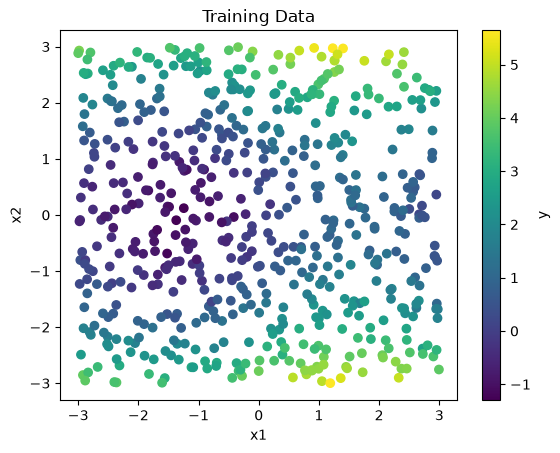

In [44]:
import matplotlib.pyplot as plt

plt.scatter(
    ds.train.X[:, 0],
    ds.train.X[:, 1],
    c=ds.train.y
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training Data")
plt.colorbar(label="y")
plt.show()

In [45]:
import importlib
import models
import numpy as np
importlib.reload(models)

from models import RandomKitchenSinks, sweep_rks_model

In [46]:
sweep_D = [20, 50, 100, 200, 500, 1000]

best_rks, best_rks_val_mse, best_D = sweep_rks_model(
    sweep_D,
    ds.train.X,
    ds.train.y,
    ds.val.X,
    ds.val.y
)

print("Best D:", best_D)
print("Best validation MSE:", best_rks_val_mse)

Best D: 50
Best validation MSE: 0.03687263083577376


In [47]:
rks_train_mses = []
rks_val_mses = []

for D in sweep_D:
    model = RandomKitchenSinks(
        D=D,
        sigma=1.0,
        ridge_lambda=1e-3
    )

    model.fit(ds.train.X, ds.train.y)

    train_pred = model.predict(ds.train.X)
    val_pred = model.predict(ds.val.X)

    train_mse = np.mean(
        (ds.train.y - train_pred) ** 2
    )

    val_mse = np.mean(
        (ds.val.y - val_pred) ** 2
    )

    rks_train_mses.append(train_mse)
    rks_val_mses.append(val_mse)

    print(
        f"D={D}: "
        f"Train MSE={train_mse:.4f}, "
        f"Val MSE={val_mse:.4f}"
    )

D=20: Train MSE=0.0365, Val MSE=0.0400
D=50: Train MSE=0.0321, Val MSE=0.0369
D=100: Train MSE=0.0311, Val MSE=0.0379
D=200: Train MSE=0.0300, Val MSE=0.0389
D=500: Train MSE=0.0291, Val MSE=0.0444
D=1000: Train MSE=0.0288, Val MSE=0.0441


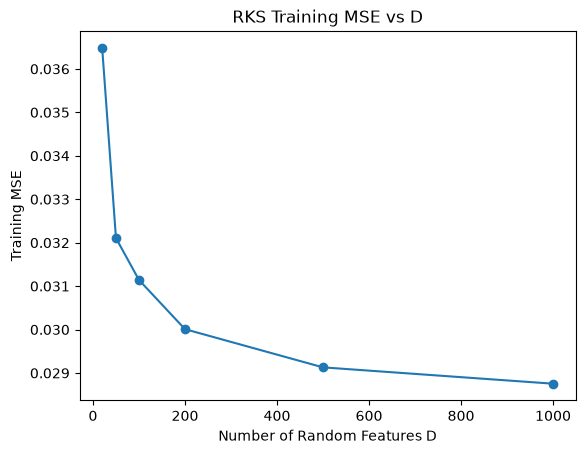

In [48]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(sweep_D, rks_train_mses, marker="o")
plt.xlabel("Number of Random Features D")
plt.ylabel("Training MSE")
plt.title("RKS Training MSE vs D")
plt.show()


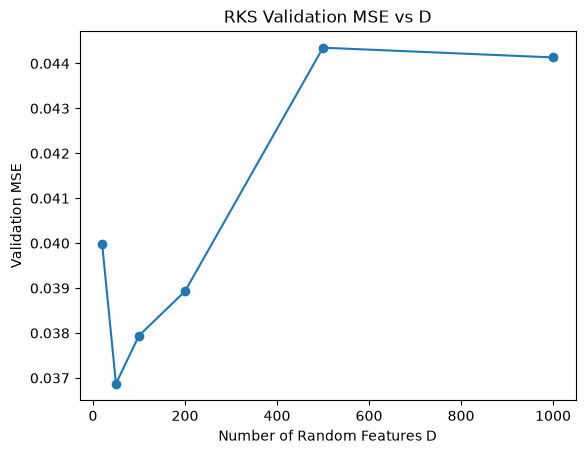

In [49]:
plt.figure()
plt.plot(sweep_D, rks_val_mses, marker="o")
plt.xlabel("Number of Random Features D")
plt.ylabel("Validation MSE")
plt.title("RKS Validation MSE vs D")
plt.show()

In [50]:
import importlib
import models

importlib.reload(models)

from models import MLP, mlp_sweep

In [51]:
sweep_hidden = [16, 32, 64, 128, 256]

best_mlp, best_mlp_val_mse, best_hidden = mlp_sweep(
    sweep_hidden,
    ds.train.X,
    ds.train.y,
    ds.val.X,
    ds.val.y
)

print("Best hidden dimension:", best_hidden)
print("Best validation MSE:", best_mlp_val_mse)

Best hidden dimension: 256
Best validation MSE: 0.03857305647230456


In [53]:
mlp_train_mses = []
mlp_val_mses = []

for d_hidden in sweep_hidden:
    model = MLP(
        d_in=ds.train.X.shape[1],
        d_hidden=d_hidden,
        d_out=1,
        lr=1e-3,
        batch_size=128,
        activation="relu",
        device="cpu"
    )

    model.fit(ds.train.X, ds.train.y)

    train_pred = model.predict(ds.train.X).reshape(-1)
    val_pred = model.predict(ds.val.X).reshape(-1)

    train_mse = np.mean(
        (ds.train.y - train_pred) ** 2
    )

    val_mse = np.mean(
        (ds.val.y - val_pred) ** 2
    )

    mlp_train_mses.append(train_mse)
    mlp_val_mses.append(val_mse)

    print(
        f"Hidden={d_hidden}: "
        f"Train MSE={train_mse:.4f}, "
        f"Val MSE={val_mse:.4f}"
    )

Hidden=16: Train MSE=0.1045, Val MSE=0.1057
Hidden=32: Train MSE=0.0534, Val MSE=0.0586
Hidden=64: Train MSE=0.0347, Val MSE=0.0418
Hidden=128: Train MSE=0.0324, Val MSE=0.0407
Hidden=256: Train MSE=0.0300, Val MSE=0.0391


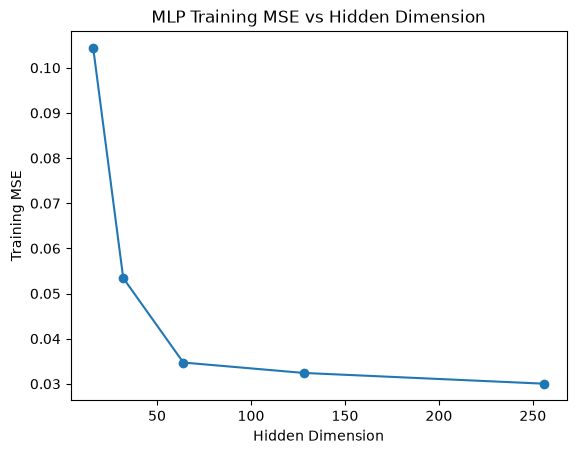

In [54]:
plt.figure()
plt.plot(sweep_hidden, mlp_train_mses, marker="o")
plt.xlabel("Hidden Dimension")
plt.ylabel("Training MSE")
plt.title("MLP Training MSE vs Hidden Dimension")
plt.show()

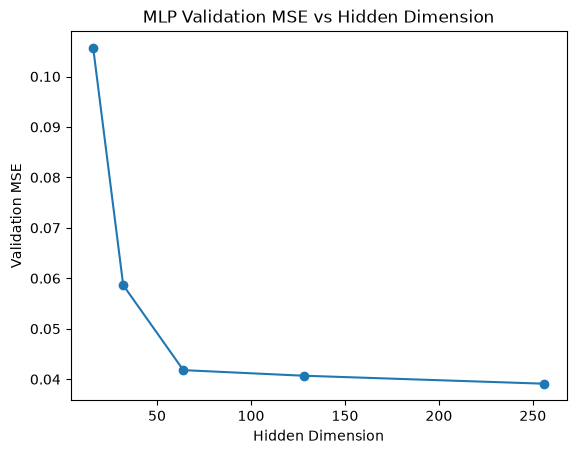

In [55]:
plt.figure()
plt.plot(sweep_hidden, mlp_val_mses, marker="o")
plt.xlabel("Hidden Dimension")
plt.ylabel("Validation MSE")
plt.title("MLP Validation MSE vs Hidden Dimension")
plt.show()

In [56]:
rks_test_pred = best_rks.predict(ds.test.X)

mlp_test_pred = best_mlp.predict(ds.test.X).reshape(-1)

print(rks_test_pred.shape)
print(mlp_test_pred.shape)

(200,)
(200,)


In [57]:
import pandas as pd

pd.DataFrame({
    "prediction": rks_test_pred
}).to_csv(
    "rks_test_predictions.csv",
    index=False
)

pd.DataFrame({
    "prediction": mlp_test_pred
}).to_csv(
    "mlp_test_predictions.csv",
    index=False
)

print("Saved both prediction files.")

Saved both prediction files.


In [58]:
from plotting import plot_surface_2d

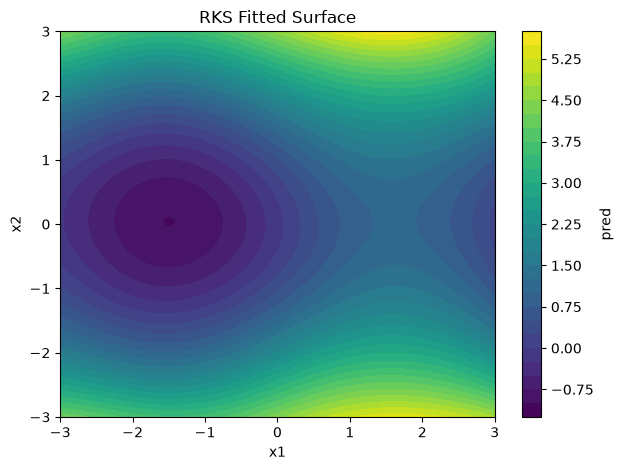

In [59]:
plot_surface_2d(
    best_rks.predict,
    (-3, 3),
    (-3, 3),
    title="RKS Fitted Surface",
    filename="rks_surface.png"
)

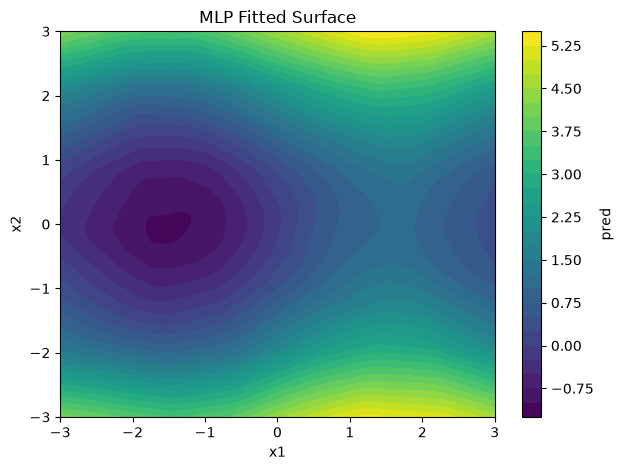

In [60]:
plot_surface_2d(
    best_mlp,
    (-3, 3),
    (-3, 3),
    title="MLP Fitted Surface",
    filename="mlp_surface.png"
)

In [61]:
import pandas as pd

rks_test_pred = best_rks.predict(ds.test.X)

pd.DataFrame({
    "prediction": rks_test_pred
}).to_csv(
    "rks_test_predictions.csv",
    index=False
)

In [62]:
mlp_test_pred = best_mlp.predict(ds.test.X).reshape(-1)

pd.DataFrame({
    "prediction": mlp_test_pred
}).to_csv(
    "mlp_test_predictions.csv",
    index=False
)